In [3]:

from google.colab import files
import pandas as pd

# Upload the downloaded CSV file
uploaded = files.upload()

# Read the CSV into a DataFrame
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Saving archive (1).zip to archive (1).zip
Dataset loaded successfully!
Dataset shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [4]:

# Check column names and data types
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of unique crops:")
print(df["label"].nunique())

print("\nNumber of samples per crop:")
print(df["label"].value_counts())


Column names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB

Missing values in each column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Number of unique crops:
22

Number of samples per crop:
label
rice           100
maize          100
chickpea       100
kid

In [5]:

# Separate input features and target
X = df.drop("label", axis=1)
y = df["label"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput feature names:")
print(X.columns.tolist())


Input features shape: (2200, 7)
Target shape: (2200,)

Input feature names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']


In [6]:

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Crop categories:")
print(label_encoder.classes_)

print("\nEncoded target shape:", y_encoded.shape)
print("First 10 encoded labels:", y_encoded[:10])


Crop categories:
['apple' 'banana' 'blackgram' 'chickpea' 'coconut' 'coffee' 'cotton'
 'grapes' 'jute' 'kidneybeans' 'lentil' 'maize' 'mango' 'mothbeans'
 'mungbean' 'muskmelon' 'orange' 'papaya' 'pigeonpeas' 'pomegranate'
 'rice' 'watermelon']

Encoded target shape: (2200,)
First 10 encoded labels: [20 20 20 20 20 20 20 20 20 20]


In [7]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 1760
Testing samples: 440


In [8]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)
print("\nFirst training sample after scaling:")
print(X_train_scaled[0])


Scaled training data shape: (1760, 7)
Scaled testing data shape: (440, 7)

First training sample after scaling:
[-1.37162846 -1.07290957 -0.67351002  0.81948109  0.92439516  0.93754456
  0.1994396 ]


In [9]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Make the experiment reproducible
tf.keras.utils.set_random_seed(42)

# Build the neural network
model_relu = Sequential([
    Dense(16, activation="relu", input_shape=(7,)),
    Dense(8, activation="relu"),
    Dense(22, activation="softmax")
])

# Configure the model for training
model_relu.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model_relu.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 22)             │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 462 (1.80 KB)

 Trainable params: 462 (1.80 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:

history_relu = model_relu.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.0384 - loss: 3.1070 - val_accuracy: 0.0881 - val_loss: 3.0544
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0952 - loss: 3.0002 - val_accuracy: 0.1449 - val_loss: 2.9576
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1896 - loss: 2.8912 - val_accuracy: 0.2386 - val_loss: 2.8348
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2607 - loss: 2.7466 - val_accuracy: 0.2983 - val_loss: 2.6728
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3232 - loss: 2.5601 - val_accuracy: 0.3466 - val_loss: 2.4664
Epoch 6/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3636 - loss: 2.3377 - val_accuracy: 0.3636 - val_loss: 2.2356
Epoch 7/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4162 - loss: 2.1011 - val_accuracy: 0.4176 - val_loss: 1.9965
Epoch 8/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4744 - loss: 1.8606 - val_accuracy: 0.4858 - val_loss:

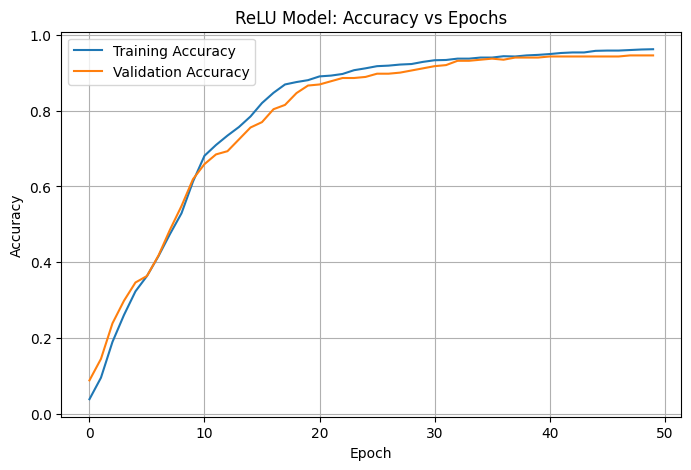

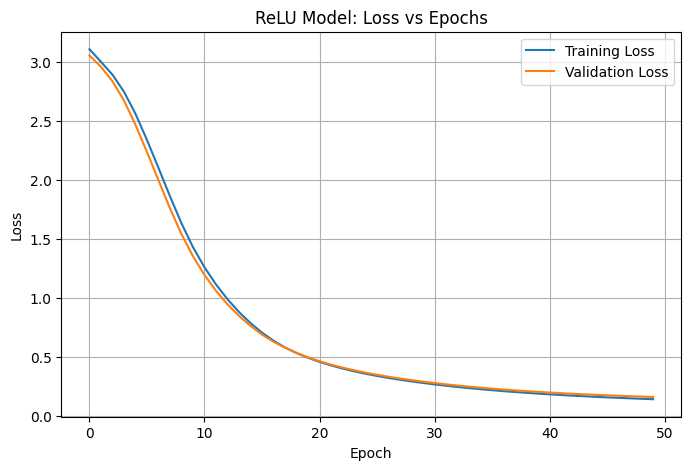

In [11]:

import matplotlib.pyplot as plt

# Plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(history_relu.history["accuracy"], label="Training Accuracy")
plt.plot(history_relu.history["val_accuracy"], label="Validation Accuracy")
plt.title("ReLU Model: Accuracy vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))
plt.plot(history_relu.history["loss"], label="Training Loss")
plt.plot(history_relu.history["val_loss"], label="Validation Loss")
plt.title("ReLU Model: Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [12]:

test_loss, test_accuracy = model_relu.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))


Test Accuracy: 96.14 %
Test Loss: 0.1328


              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      0.95      0.95        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      0.95      0.97        20
      coffee       1.00      1.00      1.00        20
      cotton       0.91      1.00      0.95        20
      grapes       1.00      1.00      1.00        20
        jute       0.86      0.90      0.88        20
 kidneybeans       0.95      1.00      0.98        20
      lentil       0.95      0.90      0.92        20
       maize       0.95      0.90      0.92        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       0.87      1.00      0.93        20
      orange       0.95      1.00      0.98        20
      papaya       1.00    

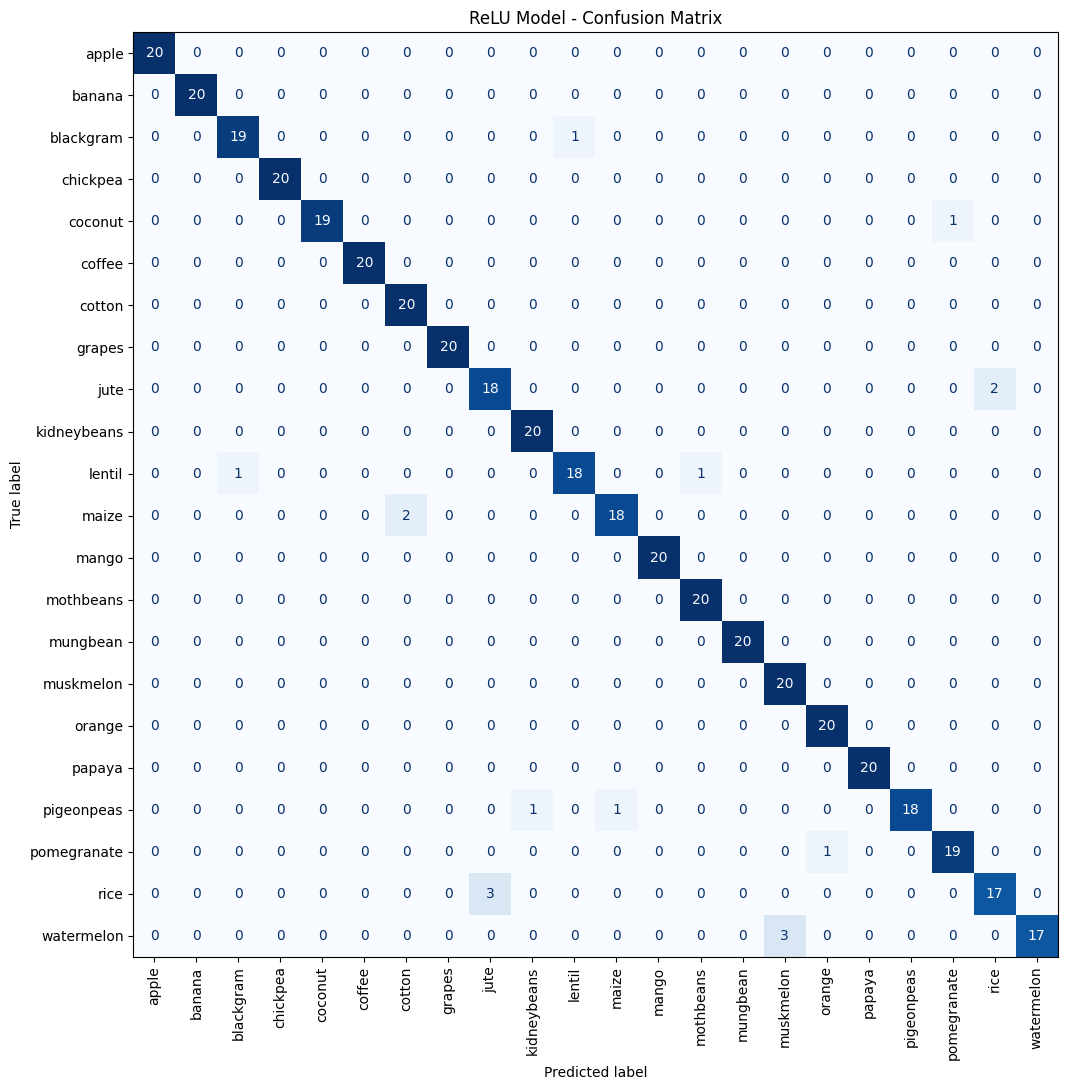

In [13]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict probabilities for the test samples
y_prob_relu = model_relu.predict(X_test_scaled, verbose=0)

# Convert probabilities into predicted class indices
y_pred_relu = np.argmax(y_prob_relu, axis=1)

# Detailed classification metrics
print(classification_report(
    y_test,
    y_pred_relu,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
cm_relu = confusion_matrix(
    y_test,
    y_pred_relu,
    labels=np.arange(len(label_encoder.classes_))
)

fig, ax = plt.subplots(figsize=(13, 11))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_relu,
    display_labels=label_encoder.classes_
)
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("ReLU Model - Confusion Matrix")
plt.tight_layout()
plt.show()


In [14]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# Build a neural network using tanh activation
tf.keras.utils.set_random_seed(42)

model_tanh = Sequential([
    Input(shape=(7,)),
    Dense(16, activation="tanh"),
    Dense(8, activation="tanh"),
    Dense(22, activation="softmax")
])

# Compile the model
model_tanh.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model_tanh.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 22)             │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 462 (1.80 KB)

 Trainable params: 462 (1.80 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:

history_tanh = model_tanh.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.0589 - loss: 3.0727 - val_accuracy: 0.1307 - val_loss: 2.9701
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.2081 - loss: 2.8674 - val_accuracy: 0.2784 - val_loss: 2.7766
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3161 - loss: 2.6909 - val_accuracy: 0.4034 - val_loss: 2.5980
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4055 - loss: 2.5235 - val_accuracy: 0.4773 - val_loss: 2.4248
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4531 - loss: 2.3619 - val_accuracy: 0.5085 - val_loss: 2.2594
Epoch 6/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4723 - loss: 2.2086 - val_accuracy: 0.5398 - val_loss: 2.1045
Epoch 7/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4964 - loss: 2.0657 - val_accuracy: 0.5597 - val_loss: 1.9612
Epoch 8/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5227 - loss: 1.9335 - val_accuracy: 0.5710 - val_loss:

In [16]:

test_loss_tanh, test_accuracy_tanh = model_tanh.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Tanh Test Accuracy:", round(test_accuracy_tanh * 100, 2), "%")
print("Tanh Test Loss:", round(test_loss_tanh, 4))


Tanh Test Accuracy: 93.86 %
Tanh Test Loss: 0.3356


In [17]:

import pandas as pd

comparison = pd.DataFrame({
    "Metric": ["Test Accuracy (%)", "Test Loss"],
    "ReLU": [
        test_accuracy * 100,
        test_loss
    ],
    "Tanh": [
        test_accuracy_tanh * 100,
        test_loss_tanh
    ]
})

print(comparison.round(4).to_string(index=False))


           Metric    ReLU    Tanh
Test Accuracy (%) 96.1364 93.8636
        Test Loss  0.1328  0.3356


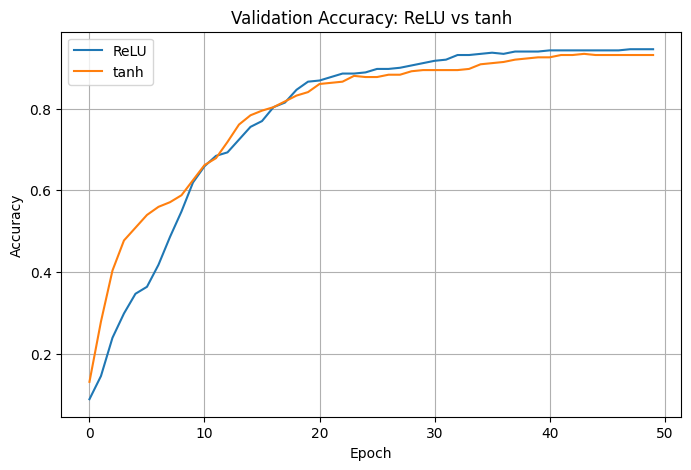

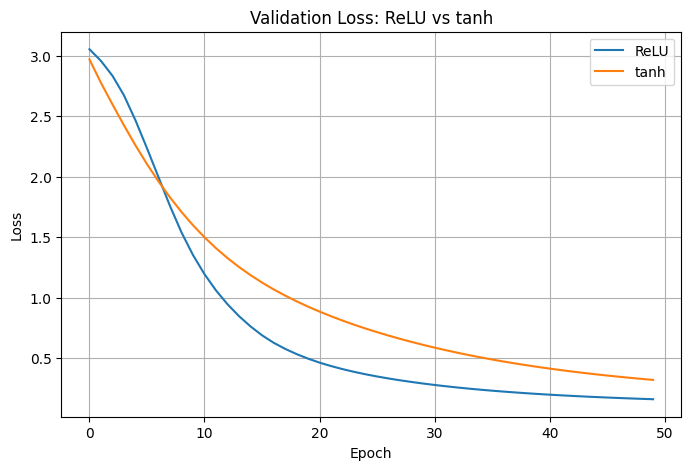

In [18]:

import matplotlib.pyplot as plt

# Compare validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history_relu.history["val_accuracy"], label="ReLU")
plt.plot(history_tanh.history["val_accuracy"], label="tanh")
plt.title("Validation Accuracy: ReLU vs tanh")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Compare validation loss
plt.figure(figsize=(8, 5))
plt.plot(history_relu.history["val_loss"], label="ReLU")
plt.plot(history_tanh.history["val_loss"], label="tanh")
plt.title("Validation Loss: ReLU vs tanh")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [19]:

import pandas as pd
import numpy as np

def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):
    input_data = pd.DataFrame([{
        "N": N,
        "P": P,
        "K": K,
        "temperature": temperature,
        "humidity": humidity,
        "ph": ph,
        "rainfall": rainfall
    }])

    input_scaled = scaler.transform(input_data)
    probabilities = model_relu.predict(input_scaled, verbose=0)[0]

    # Get indices of the three highest probabilities
    top_indices = np.argsort(probabilities)[-3:][::-1]

    print("Top 3 Crop Recommendations")
    print("-" * 35)

    for rank, index in enumerate(top_indices, start=1):
        crop = label_encoder.inverse_transform([index])[0]
        confidence = probabilities[index] * 100
        print(f"{rank}. {crop.title()} - {confidence:.2f}%")






In [20]:

recommend_crop(
    N=90,
    P=42,
    K=43,
    temperature=20.87,
    humidity=82.00,
    ph=6.50,
    rainfall=202.94
)


Top 3 Crop Recommendations
-----------------------------------
1. Rice - 72.40%
2. Jute - 26.31%
3. Coffee - 1.11%


In [21]:

import numpy as np
import pandas as pd
from sklearn.metrics import classification_report

# Get predictions from both trained models
y_pred_relu = np.argmax(
    model_relu.predict(X_test_scaled, verbose=0), axis=1
)

y_pred_tanh = np.argmax(
    model_tanh.predict(X_test_scaled, verbose=0), axis=1
)

# Generate classification reports
crop_names = label_encoder.classes_

print("========== ReLU MODEL ==========")
print(classification_report(
    y_test,
    y_pred_relu,
    labels=np.arange(len(crop_names)),
    target_names=crop_names,
    zero_division=0
))

print("\n========== TANH MODEL ==========")
print(classification_report(
    y_test,
    y_pred_tanh,
    labels=np.arange(len(crop_names)),
    target_names=crop_names,
    zero_division=0
))


========== ReLU MODEL ==========
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      0.95      0.95        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      0.95      0.97        20
      coffee       1.00      1.00      1.00        20
      cotton       0.91      1.00      0.95        20
      grapes       1.00      1.00      1.00        20
        jute       0.86      0.90      0.88        20
 kidneybeans       0.95      1.00      0.98        20
      lentil       0.95      0.90      0.92        20
       maize       0.95      0.90      0.92        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       0.87      1.00      0.93        20
      orange       0.95      1.00      0.98     

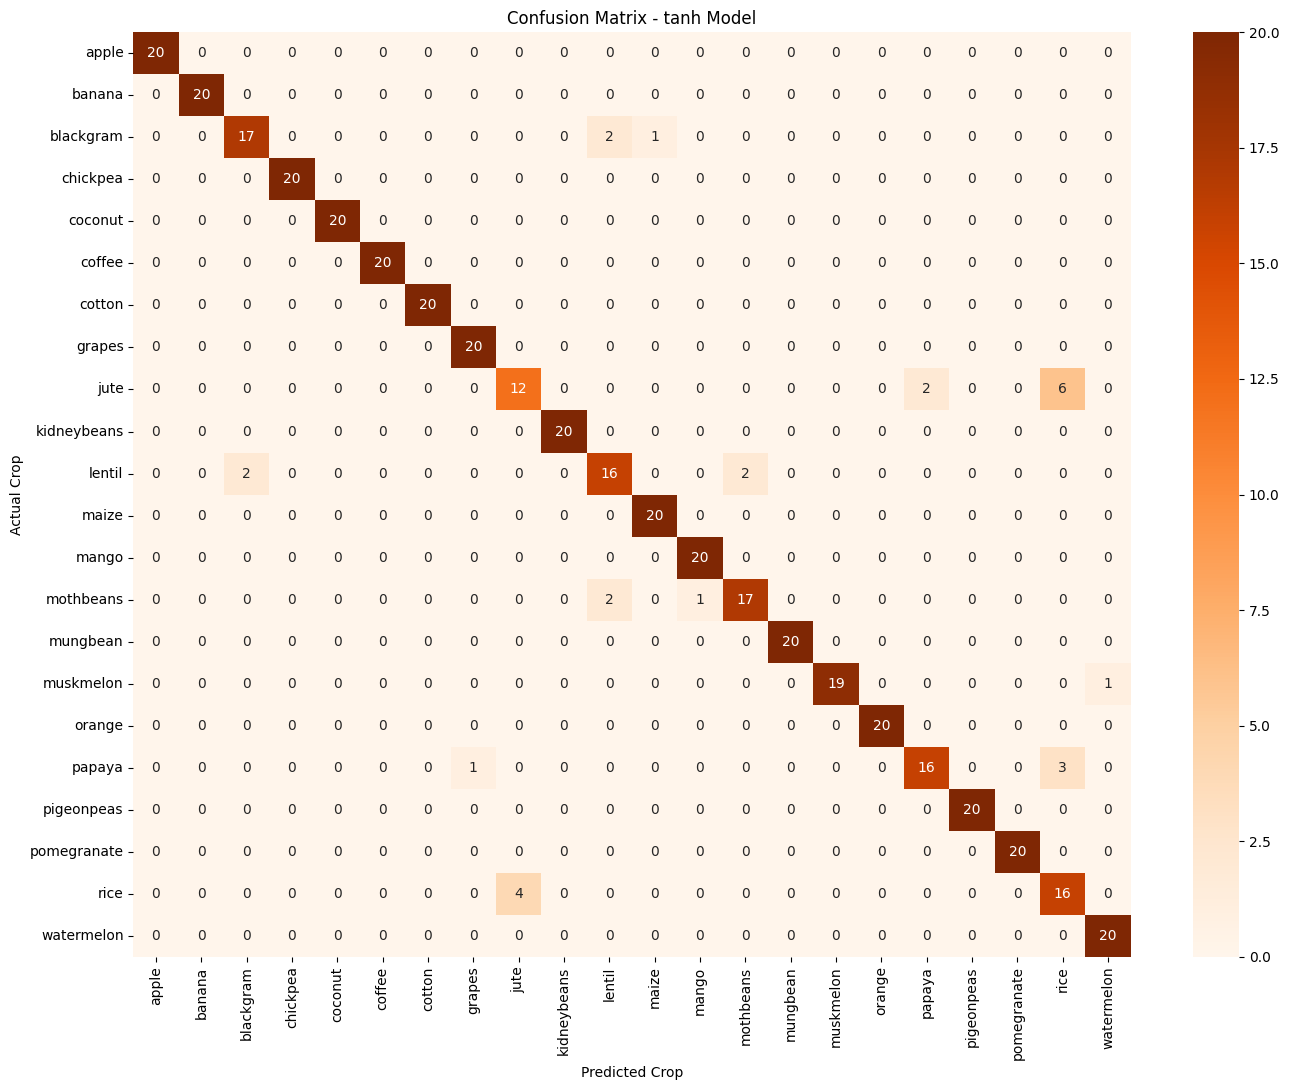

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Predict using the tanh model
y_pred_tanh = np.argmax(
    model_tanh.predict(X_test_scaled, verbose=0), axis=1
)

# Create the confusion matrix
cm_tanh = confusion_matrix(y_test, y_pred_tanh)

# Plot the confusion matrix
plt.figure(figsize=(14, 11))
sns.heatmap(
    cm_tanh,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - tanh Model")
plt.xlabel("Predicted Crop")
plt.ylabel("Actual Crop")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
!pip -q install gradio

In [24]:

import gradio as gr
import pandas as pd
import numpy as np

def recommend_crop(N, P, K, temperature, humidity, ph, rainfall):
    input_data = pd.DataFrame([{
        "N": N,
        "P": P,
        "K": K,
        "temperature": temperature,
        "humidity": humidity,
        "ph": ph,
        "rainfall": rainfall
    }])

    input_scaled = scaler.transform(input_data)
    probabilities = model_relu.predict(input_scaled, verbose=0)[0]

    top_indices = np.argsort(probabilities)[-3:][::-1]

    results = []
    for rank, index in enumerate(top_indices, start=1):
        crop = label_encoder.inverse_transform([index])[0]
        confidence = probabilities[index] * 100
        results.append(
            f"{rank}. {crop.title()} — {confidence:.2f}%"
        )

    return "\n".join(results)

demo = gr.Interface(
    fn=recommend_crop,
    inputs=[
        gr.Number(label="Nitrogen (N)", value=90),
        gr.Number(label="Phosphorus (P)", value=42),
        gr.Number(label="Potassium (K)", value=43),
        gr.Number(label="Temperature (°C)", value=20.87),
        gr.Number(label="Humidity (%)", value=82.0),
        gr.Number(label="Soil pH", value=6.5),
        gr.Number(label="Rainfall (mm)", value=202.94)
    ],
    outputs=gr.Textbox(
        label="Top 3 Crop Recommendations",
        lines=4
    ),
    title="🌱 Crop Recommendation System",
    description=(
        "Enter soil nutrient values and environmental conditions "
        "to obtain crop recommendations from the trained neural network."
    ),
    examples=[
        [90, 42, 43, 20.87, 82.0, 6.5, 202.94]
    ]
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://382969e1bdc1dcb52a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [25]:
import os
import joblib

# Create a folder for the project files
os.makedirs("crop_project_backup", exist_ok=True)

# Save the trained neural network
model_relu.save("crop_project_backup/crop_model.keras")

# Save the feature scaler
joblib.dump(
    scaler,
    "crop_project_backup/scaler.pkl"
)

# Save the crop label encoder
joblib.dump(
    label_encoder,
    "crop_project_backup/label_encoder.pkl"
)

print("Model and preprocessing files saved successfully!")

Model and preprocessing files saved successfully!
